In [ ]:
# Shared analysis modules (cca.py, emg32_cca.py, ...) live in ../src
import sys
from pathlib import Path
_src = next((p / 'src' for p in (Path.cwd(), *Path.cwd().parents) if (p / 'src' / 'cca.py').is_file()),
            Path(r'C:\Users\Kalyanbrata\Documents\Android\Analysis\src'))
sys.path.insert(0, str(_src))

# EMG32 CCA: projected spectra and CCA dimensions

This notebook follows **EMG32**, the source you identified as your live CCA NF system. Each update rebuilds CCA from the latest one-second window, performs eight power steps from equal starting weights, and scores that **same window**. It does not train once on the first second.

The main figures show both requested interpretations:
1. **Frequency spectrum of EEG projected into a CCA direction**: what rhythms are present in the mixed EEG waveform?
2. **CCA dimension spectrum**: how strong are the matched dimensions, ordered from strongest to weakest?

We also inspect the board's logged scores and feedback. The board only computes the approximate leading direction; the full two-dimensional decomposition is an offline diagnostic. Projection waveforms and PSDs are also offline visualizations, not extra signals sent by the firmware.

Sources: [Config.h](EMG32/include/Config.h), [Filters.cpp](EMG32/src/Filters.cpp), [Analysis.cpp](EMG32/src/Analysis.cpp), [CcaNeurofeedback.cpp](EMG32/src/CcaNeurofeedback.cpp), [smoother](EMG32/include/CcaNeurofeedback.h), [reference tables](EMG32/include/CcaRefTables.h), [TCP bridge](EMG32/utils/eeg_tcp_server.py). The numerical and loading code is in [emg32_cca.py](emg32_cca.py).

**Why hardware-friendly?** The matching idea is the usual CCA idea. EMG32 precomputes the references, shares the EEG inverse across targets, and estimates only the leading direction with eight power steps. Regularization and limited precision/iterations make this an approximate implementation, not a separate first-second calibration procedure.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal
from IPython.display import display
from emg32_cca import *

plt.rcParams.update({"figure.dpi":110,"axes.spines.top":False,"axes.spines.right":False})
ROOT = Path.cwd()
if not (ROOT/"EMG32").exists(): ROOT = Path(__import__("emg32_cca").__file__).parent.parent
records, audit = load_recordings(ROOT)
display(audit)
display(pd.DataFrame({
    "Setting":["Sample rate","Window / hop","Physical channels","CAR","Targets / harmonics","Power steps",
               "XX diagonal addition","Feedback gain (current source)","Median","Input to CCA"],
    "EMG32":["250 Hz","250 / 25 samples","C9–C24 (16 channels)","Off","17 / 19 Hz; fundamental only","8, equal restart",
             "max(mean diagonal × 1e-5, 1e-6)","2","5 values; first 5 bypass at board startup",
             "Board-filtered µV; channel means removed within each window"]
}))


,game,recording,signal_rows,cca_updates,signal_gaps,feature_gaps,trials,valid_windows,gain1_MAE,gain1_max,current_gain_MAE
0,Paddle,eeg_20261006_153213,137182,5488,0,0,48,959,3.046543e-07,0.000001,0.074588
1,Paddle,eeg_20261006_155629,107492,4292,0,1,48,937,2.906791e-07,0.000001,0.093864
2,Leaf,eeg_20261006_160348,106878,4274,0,1,24,480,3.007517e-07,0.000001,0.074385
3,Leaf,eeg_20261006_161145,104675,4187,0,0,24,480,3.192052e-07,0.000001,0.078136


,Setting,EMG32
0,Sample rate,250 Hz
1,Window / hop,250 / 25 samples
2,Physical channels,C9–C24 (16 channels)
3,CAR,Off
4,Targets / harmonics,17 / 19 Hz; fundamental only
5,Power steps,"8, equal restart"
6,XX diagonal addition,"max(mean diagonal × 1e-5, 1e-6)"
7,Feedback gain (current source),2
8,Median,5 values; first 5 bypass at board startup
9,Input to CCA,Board-filtered µV; channel means removed withi...


## Which data enters the calculation?

The `signals.csv` columns are already **board-filtered microvolts** (TYPE_PROC): raw count conversion → raw clamp → glitch gate → stateful DC blocker → 61-tap FIR → output clamp. We use C9–C24, as selected by the active 16-channel montage. CAR is off. Do not apply the MATLAB delayed subtraction, a second FIR, or multiply these µV values by a counts conversion.

We align each window to its **actual logged CCA sequence number**, not a new grid beginning at each trial. The last 250 recorded samples must be contiguous and finite. A window may contain pretrial data. Trial markers only choose which updates to summarize; they do not reset the ring, weights' initial rule, filters, or median state.

We retain the same four recordings selected in the previous analysis. For plots, each trial contributes its available updates from start to <2 seconds or its earlier stop marker 30. Average linear PSD within each trial, then give each trial equal weight. No 250 µV artifact rejection is imposed: that was an offline rule, not this firmware's NF rule. Overlapping windows are not independent observations. Physical electrode names beyond C9–C24 are not inferred.

## Recorded feedback and the current checkout differ

The logger's explicit `is_cca=1` layout is: `v1=fb_AgtB, v2=fb_BgtA, v3=score_A, v4=score_B`. Other rows are excluded, including duplicated score-first rows.

Current source: `median5(clip(2 × (score_17 − score_19), −1, 1))`. The October 6 recordings instead match **gain 1** to CSV rounding when five consecutive logged hops are available. That is evidence about the recordings; it does not identify the exact firmware binary flashed that day. We preserve actual recorded NF and compare both formulas. The initial smoother state predates these files, so its first four logged outputs cannot be reconstructed. Missing feedback updates invalidate five-point replay until the gap leaves the buffer. The firmware bypasses the median for its first five successful pushes after `begin()`, then applies it from the sixth.

The bridge copies the board feedback into `nf.txt` at a wall-clock throttle of at most 10 writes/s. Logged board updates are not proof that every value was consumed by the game.

Gain-1 maximum error over eligible consecutive history: 1.0000000000842668e-06


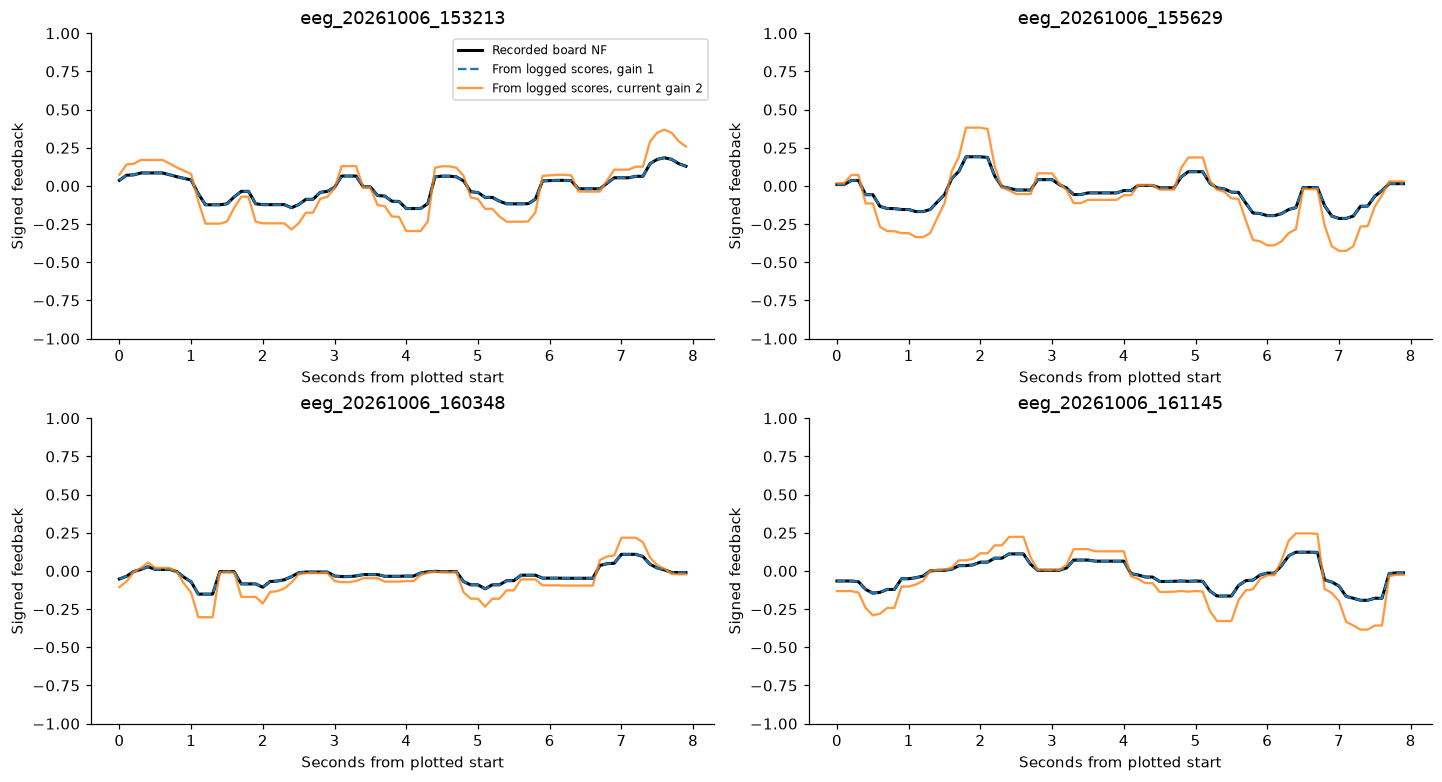

In [2]:
fig, axes = plt.subplots(2,2,figsize=(13,7),constrained_layout=True)
for ax, rec in zip(axes.flat,records):
    f=rec["features"].iloc[30:110]
    t=(f.seq-f.seq.iloc[0])/FS
    ax.plot(t,f.recorded_nf,label="Recorded board NF",lw=2,color="black")
    ax.plot(t,f.nf_gain1,label="From logged scores, gain 1",ls="--")
    ax.plot(t,f.nf_current_gain,label=f"From logged scores, current gain {GAIN:g}",alpha=.8)
    ax.set(title=rec["name"],xlabel="Seconds from plotted start",ylabel="Signed feedback",ylim=(-1,1))
axes.flat[0].legend(fontsize=8)
plt.show()
print("Gain-1 maximum error over eligible consecutive history:",audit.gain1_max.max())
assert audit.gain1_max.max() < 2e-6

## Recover the current-window directions

The float32 model reproduces the firmware's accumulation order, Gauss–Jordan inversion, and eight iterations, using the **compiled reference tables**. ESP32 compiler arithmetic and the rounded CSV input can still differ. We compare every reconstructed score with the logged score and report discrepancies rather than calling this an exact historical replay.

For the full dimension diagnostic, use stable double-precision sums and a Cholesky/SVD solution with the same relative regularization rule. The reference table has only sine and cosine, so at most **two** matched dimensions exist per target; the remaining 14 mathematical strengths are zero. Finite-step firmware scores can differ from these strengths. The score uses `sqrt(max(vᵀ M v,0))`, without an upper clamp. Because M is nonsymmetric and the iteration is approximate, do not relabel every firmware score as an exact Pearson correlation.

For PSD, normalize each spatial direction to Euclidean length one. This keeps the projected waveform in µV with a stated scale; the firmware already normalizes its power-iteration vector that way. Diagnostic CCA metric normalization has a different scale. Calculate each PSD on the same window that fitted its direction; this is descriptive, not held-out validation.

In [3]:
summaries=[]; comparisons=[]; example=None
for rec in records:
    for trial in rec["trials"]:
        baseline=[]; primary=[]; exact=[]; strengths=[]; rows=[]; weights=[]
        for row,x in current_windows(rec,trial):
            prepared=prepare_window(x)
            fits=[fit_window(x,f,prepared) for f in TARGETS]
            frequencies,p0=psd(x)
            baseline.append(p0)
            primary.append(np.stack([psd(fit["hw_U"])[1] for fit in fits],axis=-1))
            exact.append(np.stack([psd(fit["exact_U"])[1] for fit in fits],axis=-1))
            strengths.append(np.stack([fit["strengths_all"] for fit in fits],axis=-1))
            weights.append(np.stack([fit["hw_weights"] for fit in fits],axis=-1))
            calculated=[fit["hardware_score"] for fit in fits]
            comparisons.append({"recording":rec["name"],"seq":row.seq,
                                "error17":calculated[0]-row.v3,"error19":calculated[1]-row.v4,
                                "calculated17":calculated[0],"logged17":row.v3,
                                "calculated19":calculated[1],"logged19":row.v4})
            rows.append(row)
            if example is None and row.time>=1:
                example={"record":rec,"trial":trial,"row":row,"input":x.copy(),"fits":fits}
        if rows:
            summaries.append({"game":trial["game"],"code":trial["code"],"recording":trial["recording"],
                              "trial":trial["trial"],"n_updates":len(rows),
                              "baseline":np.mean(baseline,axis=0),"primary":np.mean(primary,axis=0),
                              "exact":np.mean(exact,axis=0),"strengths":np.mean(strengths,axis=0),
                              "rows":rows,"weights":np.array(weights)})
comparisons=pd.DataFrame(comparisons)
error_audit=comparisons.groupby("recording")[["error17","error19"]].agg(
    [lambda s:np.mean(abs(s)),lambda s:np.max(abs(s))])
error_audit.columns=["17 MAE","17 max","19 MAE","19 max"]
display(error_audit)
display(pd.DataFrame([{k:s[k] for k in ("game","code","recording","trial","n_updates")} for s in summaries]))
print(len(summaries),"trials;",len(comparisons),"reconstructed current windows")
assert len(summaries)>0 and all(np.isfinite(s["primary"]).all() for s in summaries)
assert all(fit["X"].shape==(250,16) and fit["Y"].shape==(250,2) for fit in example["fits"])

144 trials; 2856 reconstructed current windows


,17 MAE,17 max,19 MAE,19 max
recording,,,,
eeg_20261006_153213,0.000971,0.064922,0.001304,0.026288
eeg_20261006_155629,0.000041,0.002149,0.000063,0.004511
eeg_20261006_160348,0.000004,0.000866,0.000002,0.000031
eeg_20261006_161145,0.000003,0.000151,0.000019,0.006924


,game,code,recording,trial,n_updates
0,Paddle,21,eeg_20261006_153213,1,20
1,Paddle,20,eeg_20261006_153213,2,20
2,Paddle,20,eeg_20261006_153213,3,20
3,Paddle,20,eeg_20261006_153213,4,20
4,Paddle,21,eeg_20261006_153213,5,20
...,...,...,...,...,...
139,Leaf,20,eeg_20261006_161145,20,20
140,Leaf,20,eeg_20261006_161145,21,20
141,Leaf,20,eeg_20261006_161145,22,20
142,Leaf,21,eeg_20261006_161145,23,20


These residuals limit historical replay accuracy. The plots below describe the EMG32 algorithm
applied to the recorded board-filtered windows; recorded NF stays separate.


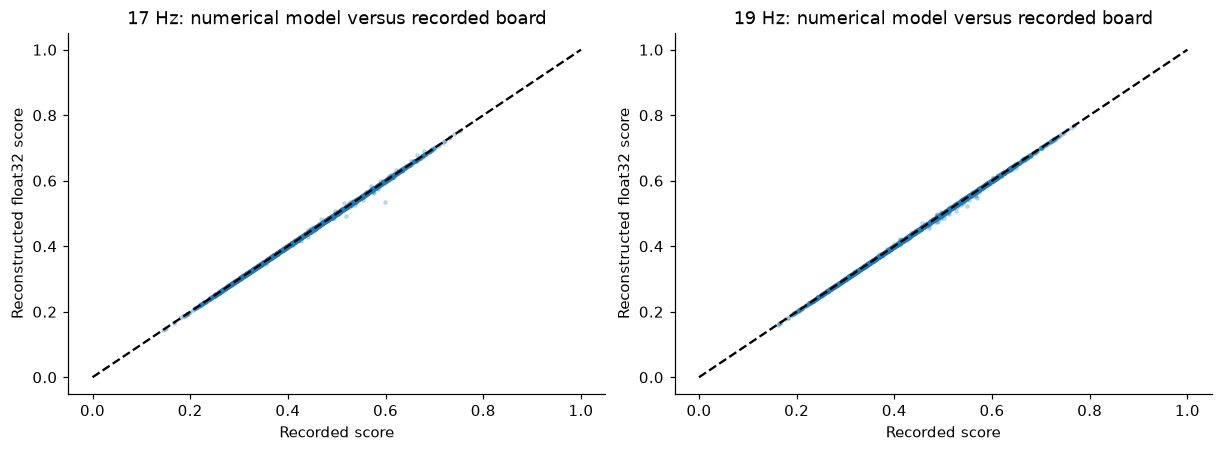

In [4]:
fig, axes=plt.subplots(1,2,figsize=(11,4),constrained_layout=True)
for ax,f in zip(axes,TARGETS):
    ax.scatter(comparisons[f"logged{int(f)}"],comparisons[f"calculated{int(f)}"],s=5,alpha=.2)
    ax.plot([0,1],[0,1],"k--")
    ax.set(title=f"{f:g} Hz: numerical model versus recorded board",
           xlabel="Recorded score",ylabel="Reconstructed float32 score")
plt.show()
print("These residuals limit historical replay accuracy. The plots below describe the EMG32 algorithm")
print("applied to the recorded board-filtered windows; recorded NF stays separate.")

## 1. Frequency spectrum after projection

For each target, the waveform is `u = centered_EEG @ weights_after_8_steps`.
Its PSD tells you **what frequencies occur in that EEG mixture**. Multiplying the original channel PSD by a CCA score does not generate this projection: time series must be mixed before the PSD is calculated.

The first column pools all trials; the other columns separate the task labels from the original analysis. Gray traces are the 16 input-channel spectra; the black line is their mean linear PSD. Blue/orange traces are target-specific projected spectra. Fit both targets for every trial regardless of its label. The one-second plotting window gives 1 Hz FFT bins; DPSS NW=1, K=1 is an offline plotting choice, not a firmware taper.

The scales can be very different: correlated channels can cancel in a normalized mixture, leaving a small projected voltage even when the CCA match is strong. A stronger matching score does not necessarily mean more absolute projected power. The observed condition differences are descriptive; no significance test or artifact-based exclusion is imposed here.

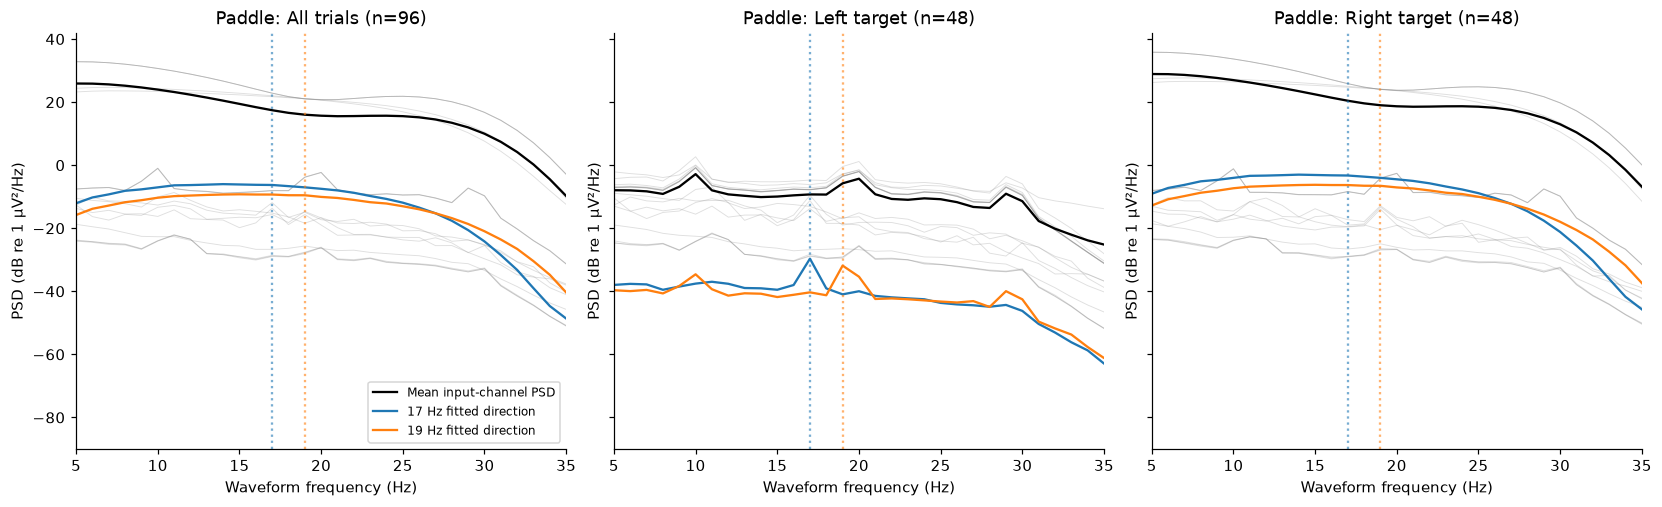

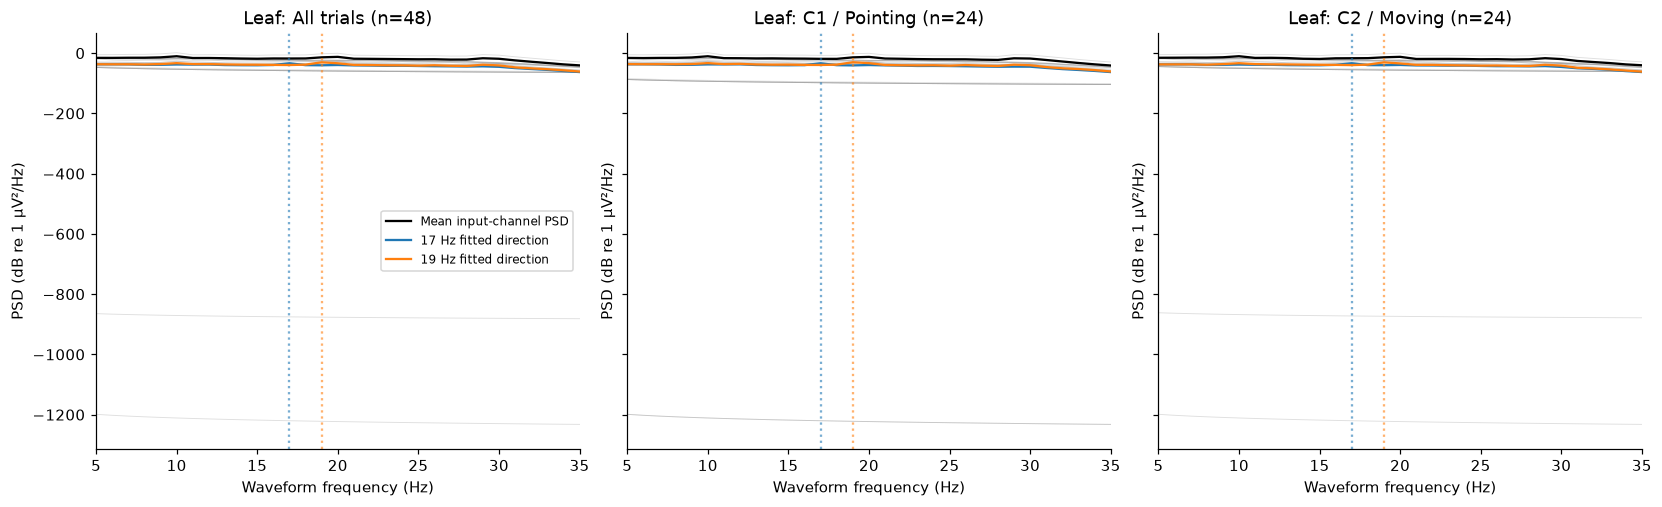

In [5]:
for game in FILES:
    conditions=[None,20,21]
    fig,axes=plt.subplots(1,3,figsize=(15,4.5),sharey=True,constrained_layout=True)
    for ax,condition in zip(axes,conditions):
        selected=[s for s in summaries if s["game"]==game and (condition is None or s["code"]==condition)]
        base=np.mean([s["baseline"] for s in selected],axis=0)
        projection=np.mean([s["primary"] for s in selected],axis=0)
        for j in range(16): ax.plot(frequencies,db(base[:,j]),color="gray",alpha=.25,lw=.6)
        ax.plot(frequencies,db(base.mean(1)),color="black",label="Mean input-channel PSD")
        for j,f in enumerate(TARGETS):
            ax.plot(frequencies,db(projection[:,j]),label=f"{f:g} Hz fitted direction")
            ax.axvline(f,ls=":",color=("C0","C1")[j],alpha=.6)
        title="All trials" if condition is None else LABELS[game][condition]
        ax.set(title=f"{game}: {title} (n={len(selected)})",xlim=(5,35),
               xlabel="Waveform frequency (Hz)",ylabel="PSD (dB re 1 µV²/Hz)")
    axes[0].legend(fontsize=8);plt.show()

## 2. Strength spectrum across CCA dimensions

Here the horizontal axis is **dimension number**, not Hz. Each target has its own independently fitted dimensions. The bars give the within-trial mean strength and then the across-trial mean. Dimension 1 is the strongest exact mathematical match; dimension 2 is the next distinct match under the CCA metric. The 14 zeros follow from having two reference columns, not from finding 16 separately useful waveforms.

These are regularized matching strengths; the board does not transmit this full spectrum.

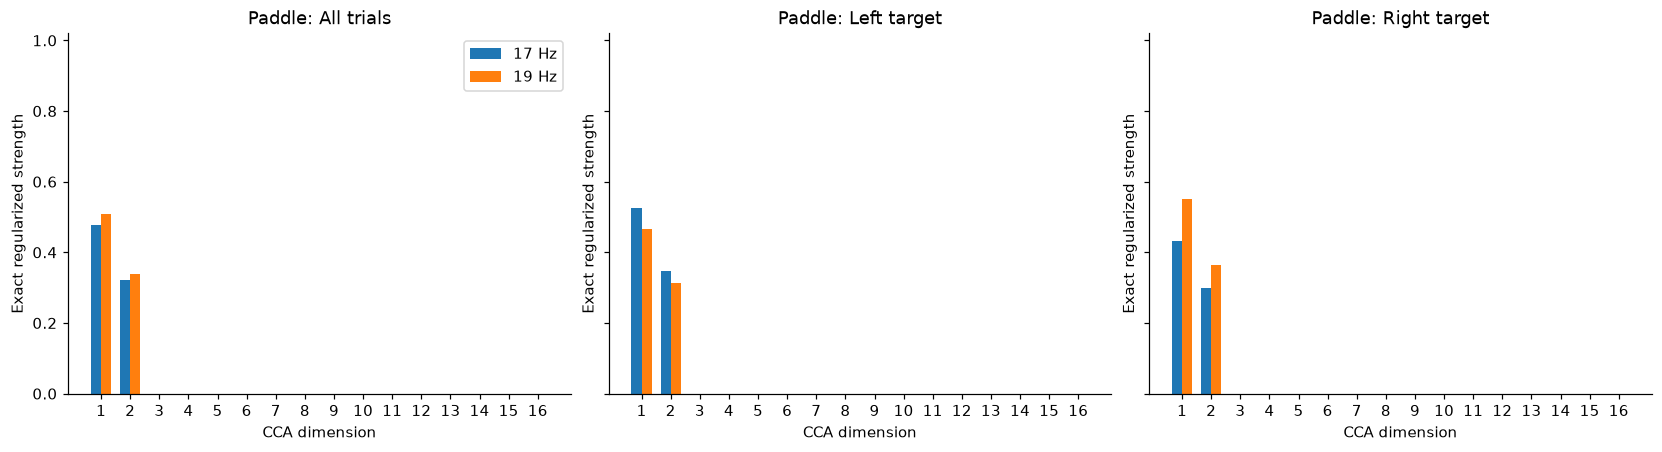

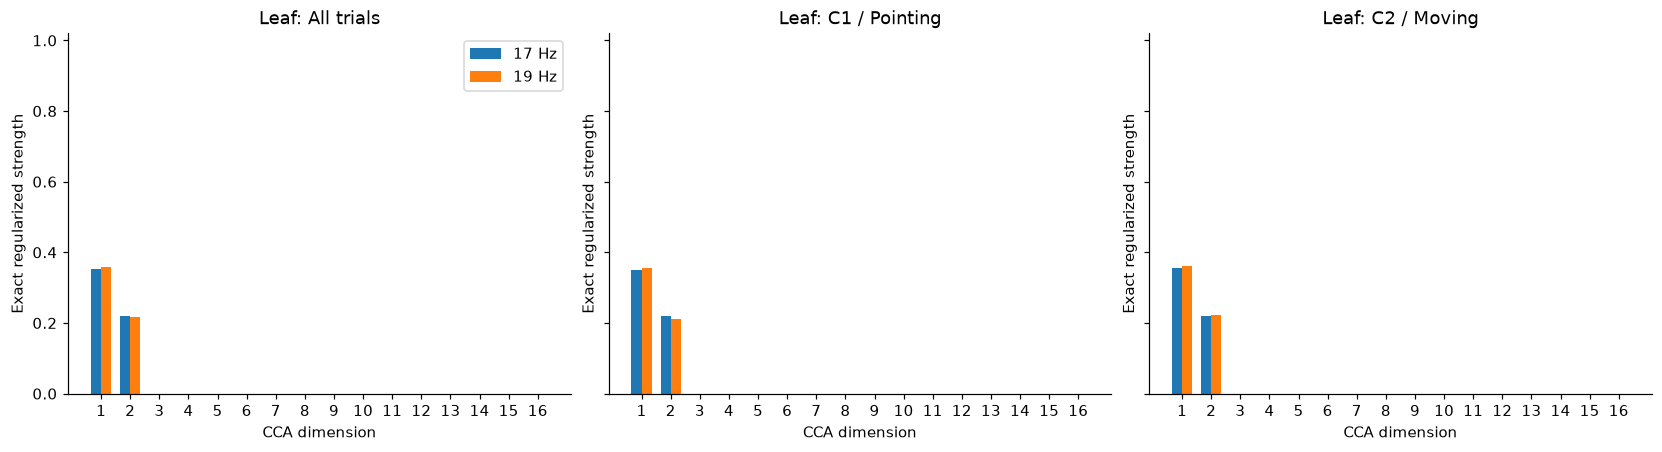

In [6]:
for game in FILES:
    fig,axes=plt.subplots(1,3,figsize=(15,4),sharey=True,constrained_layout=True)
    for ax,condition in zip(axes,(None,20,21)):
        selected=[s for s in summaries if s["game"]==game and (condition is None or s["code"]==condition)]
        a=np.mean([s["strengths"] for s in selected],axis=0)
        for j,f in enumerate(TARGETS):
            ax.bar(np.arange(1,17)+(j-.5)*.35,a[:,j],width=.35,label=f"{f:g} Hz")
        title="All trials" if condition is None else LABELS[game][condition]
        ax.set(title=f"{game}: {title}",xlabel="CCA dimension",ylabel="Exact regularized strength",
               xticks=range(1,17),ylim=(0,1.02))
    axes[0].legend();plt.show()

## What do the second dimension and projection coordinates look like?

The next PSDs use both **exact diagnostic** directions (stable double precision). The second direction is a second mixture of the same EEG window; it is not automatically a second harmonic, a second electrode, or another brain region. At 17 Hz or 19 Hz, the reference mixture can change phase.

The coordinate plot below uses metric-normalized exact CCA coordinates for one window. Its path shows one point per time sample in a two-dimensional coordinate system. These axes are refitted next update: never concatenate changing coordinates into one stationary long waveform and take its FFT.

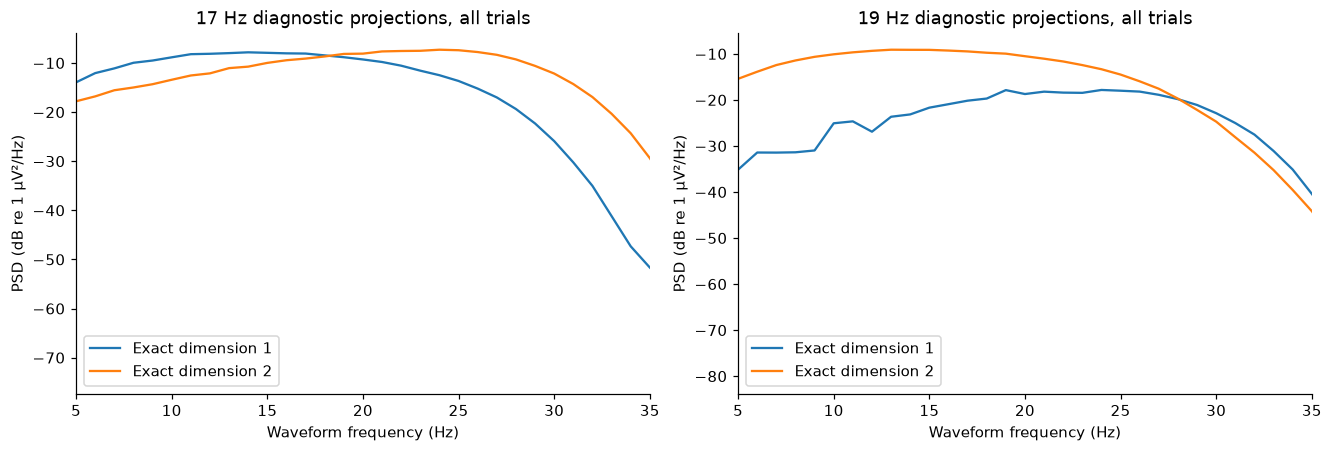

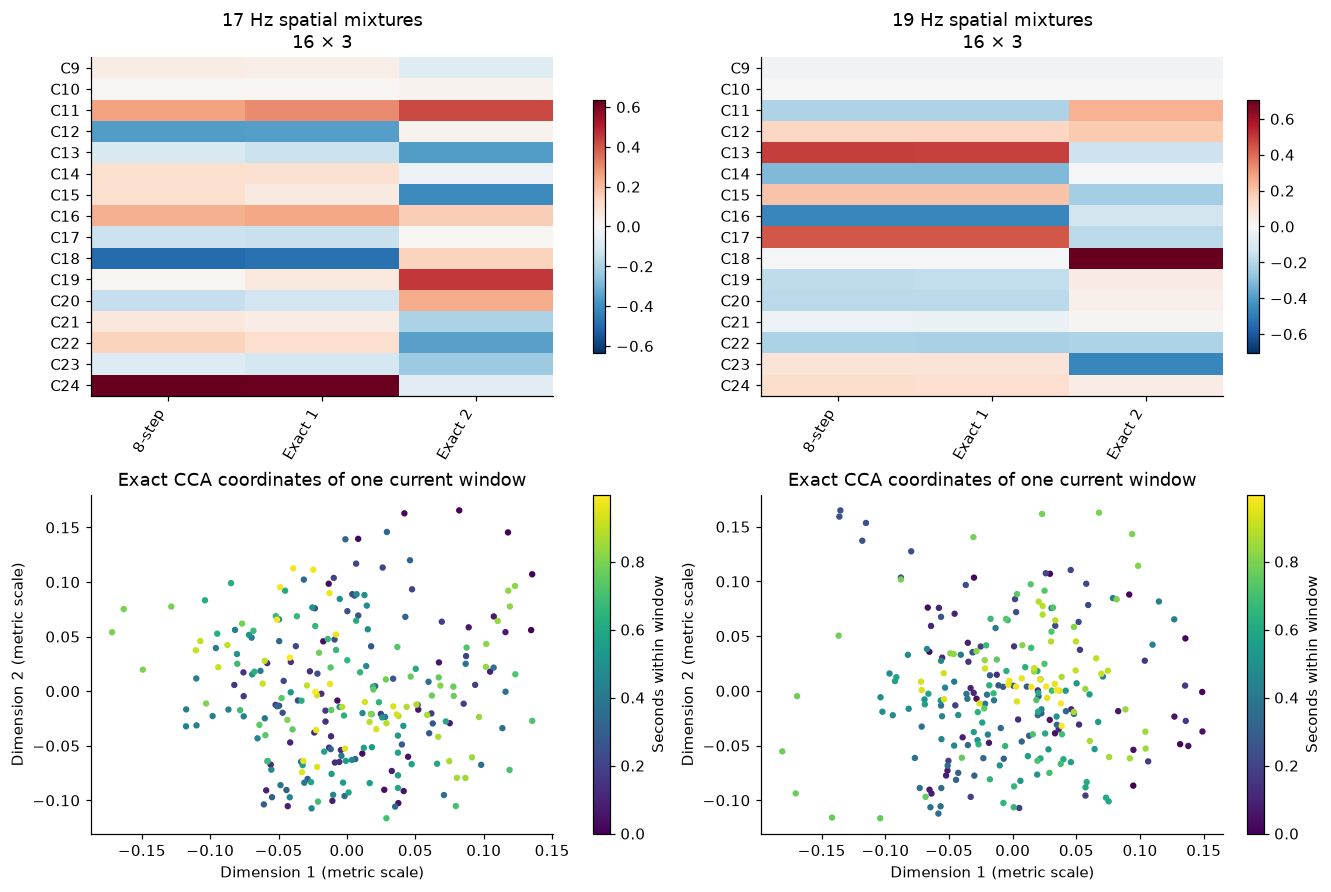

In [7]:
fig,axes=plt.subplots(1,2,figsize=(12,4),constrained_layout=True)
for ax,fidx in zip(axes,range(2)):
    for dimension in range(2):
        power=np.mean([s["exact"][:,dimension,fidx] for s in summaries],axis=0)
        ax.plot(frequencies,db(power),label=f"Exact dimension {dimension+1}")
    ax.set(title=f"{TARGETS[fidx]:g} Hz diagnostic projections, all trials",xlim=(5,35),
           xlabel="Waveform frequency (Hz)",ylabel="PSD (dB re 1 µV²/Hz)")
    ax.legend()
plt.show()
fig,axes=plt.subplots(2,2,figsize=(12,8),constrained_layout=True)
t=np.arange(WINDOW)/FS
for j,fit in enumerate(example["fits"]):
    heatmap(axes[0,j],np.column_stack((fit["hw_weights"],fit["unit_weights"])),
            f"{fit['frequency']:g} Hz spatial mixtures",CHANNEL_NAMES,["8-step","Exact 1","Exact 2"])
    scatter=axes[1,j].scatter(fit["U"][:,0],fit["U"][:,1],c=t,cmap="viridis",s=10)
    axes[1,j].set(title="Exact CCA coordinates of one current window",
                  xlabel="Dimension 1 (metric scale)",ylabel="Dimension 2 (metric scale)")
    fig.colorbar(scatter,ax=axes[1,j],label="Seconds within window")
plt.show()

## Changing weights and what gets sent as NF

The heat maps show weights rebuilt at each logged update for one example trial. Their signs are arbitrary for a projection PSD; firmware power iteration is shown without sign alignment. The equations, input units, montage and iteration rule follow the current checkout. The logged feedback belongs to the historical recording.

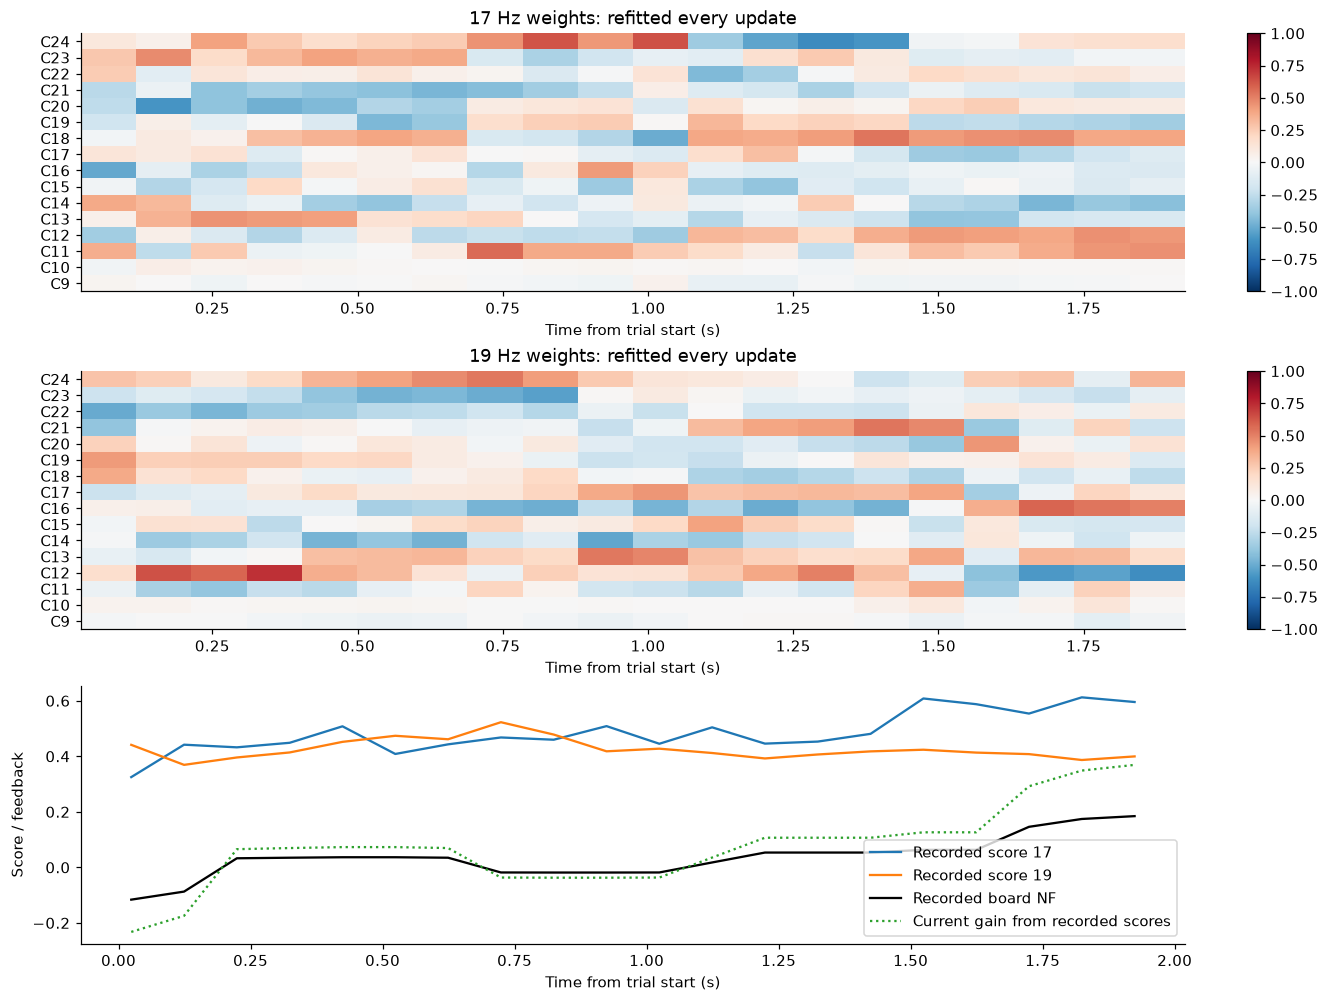

In [8]:
chosen=next(s for s in summaries if s["recording"]==example["trial"]["recording"]
            and s["trial"]==example["trial"]["trial"])
times=np.array([row.time for row in chosen["rows"]])
fig,axes=plt.subplots(3,1,figsize=(12,9),constrained_layout=True)
for j in range(2):
    im=axes[j].imshow(chosen["weights"][:,:,j].T,aspect="auto",origin="lower",
                      extent=[times[0],times[-1],-.5,15.5],cmap="RdBu_r",vmin=-1,vmax=1)
    axes[j].set(title=f"{TARGETS[j]:g} Hz weights: refitted every update",
                yticks=range(16),yticklabels=CHANNEL_NAMES,xlabel="Time from trial start (s)")
    fig.colorbar(im,ax=axes[j])
rows=chosen["rows"]
axes[2].plot(times,[r.v3 for r in rows],label="Recorded score 17")
axes[2].plot(times,[r.v4 for r in rows],label="Recorded score 19")
axes[2].plot(times,[r.recorded_nf for r in rows],label="Recorded board NF",color="black")
axes[2].plot(times,[r.nf_current_gain for r in rows],label="Current gain from recorded scores",ls=":")
axes[2].set(xlabel="Time from trial start (s)",ylabel="Score / feedback");axes[2].legend()
plt.show()

## Interpretation checklist

- **Projected PSD**: frequency content in a target-fitted channel mixture.
- **Dimension spectrum**: ordered strengths of the full regularized CCA problem, offline.
- **Firmware score**: one scalar per target from eight restarted power steps.
- **Board NF**: clipped difference with continuous five-point median state; current gain is 2, logs support historical gain 1.
- **Exact coordinates**: points in a window-specific CCA coordinate system, not a continuous signal with fixed axes.

Scores and projections fit and describe the same data, so a good match does not establish out-of-sample performance, attention, or causal neural origin. A scalar score is dimensionless; PSD carries power units. For independent evaluation, a fixed-weight train/test analysis would be a separate experiment.

Run all cells from this project directory with NumPy, pandas, SciPy, Matplotlib and IPython. The original `analysis.ipynb`, `cca.py`, MATLAB scripts and EMG32 firmware remain unchanged.